Epoch 1/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0628 - val_loss: 0.0328
Epoch 2/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0242 - val_loss: 0.0138
Epoch 3/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0151 - val_loss: 0.0092
Epoch 4/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0130 - val_loss: 0.0087
Epoch 5/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0121 - val_loss: 0.0088
MODEL RESULTS
MAE:  3.387 kW
RMSE: 5.334 kW


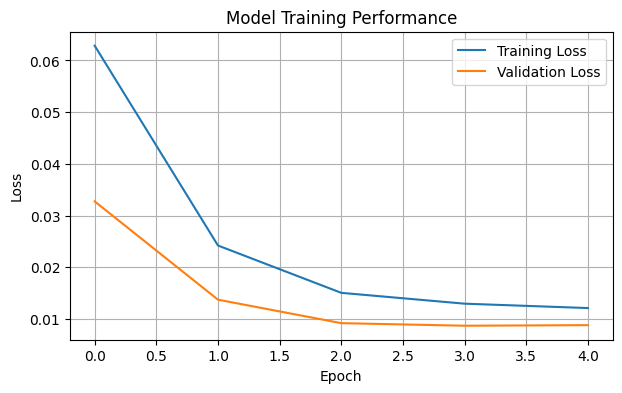

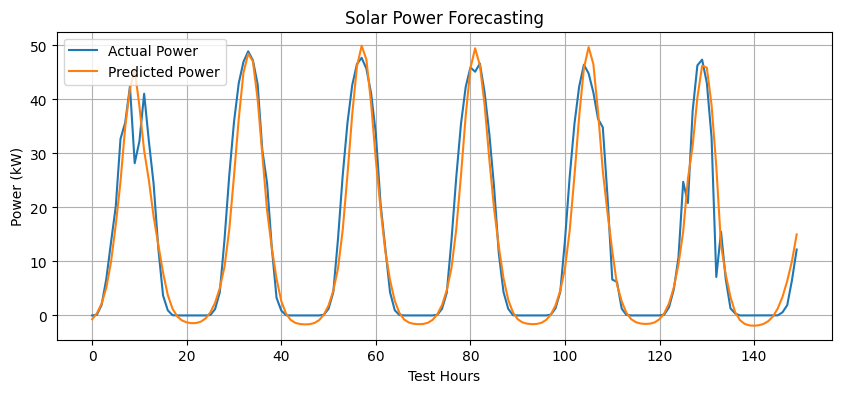

Predictions saved to renewcast_predictions.csv


In [ ]:
# RENEWCAST AI: Solar Power Forecasting

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Load real solar power dataset
url = "https://raw.githubusercontent.com/upb-nlp/PV-Generation-Dataset/main/site_a/site_a_hourly_weather.csv"
df = pd.read_csv(url)

# 2. Prepare data
power = df["active_power_kw"].dropna().tail(3000).values.reshape(-1, 1)

split_point = int(len(power) * 0.8)
scaler = MinMaxScaler()
scaler.fit(power[:split_point])
scaled = scaler.transform(power)

# 3. Create sequences: previous 24 hours -> next hour
X, y = [], []
for i in range(24, len(scaled)):
    X.append(scaled[i-24:i])
    y.append(scaled[i])

X, y = np.array(X), np.array(y)
split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# 4. Build a simple LSTM model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(24, 1)),
    tf.keras.layers.LSTM(16),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer="adam", loss="mse")
history = model.fit(
    X_train, y_train,
    epochs=5, batch_size=32,
    validation_split=0.1, verbose=1
)

# 5. Predict and evaluate
pred = model.predict(X_test, verbose=0)
actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(pred)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MODEL RESULTS")
print(f"MAE:  {mae:.3f} kW")
print(f"RMSE: {rmse:.3f} kW")

# 6. Graph 1: Training and validation loss
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Training Performance")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# 7. Graph 2: Actual vs predicted solar power
plt.figure(figsize=(10, 4))
plt.plot(actual[:150], label="Actual Power")
plt.plot(predicted[:150], label="Predicted Power")
plt.title("Solar Power Forecasting")
plt.xlabel("Test Hours")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid(True)
plt.show()

# 8. Save predictions
results = pd.DataFrame({
    "Actual Power (kW)": actual.flatten(),
    "Predicted Power (kW)": predicted.flatten()
})
results.to_csv("renewcast_predictions.csv", index=False)
print("Predictions saved to renewcast_predictions.csv")